In [1]:
pip install -q kagglehub torchmetrics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Лабораторная работа 3: Transfer Learning на Garbage Classification

# !pip install -q kagglehub torchmetrics

import os, random, copy, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.models import (
    ResNet18_Weights, ResNet50_Weights,
    EfficientNet_B0_Weights,
)
from torchmetrics.classification import MulticlassF1Score

import kagglehub

Классы: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Всего изображений: 2527
Форма изображения: (384, 512, 3)
Метка (пример): 0


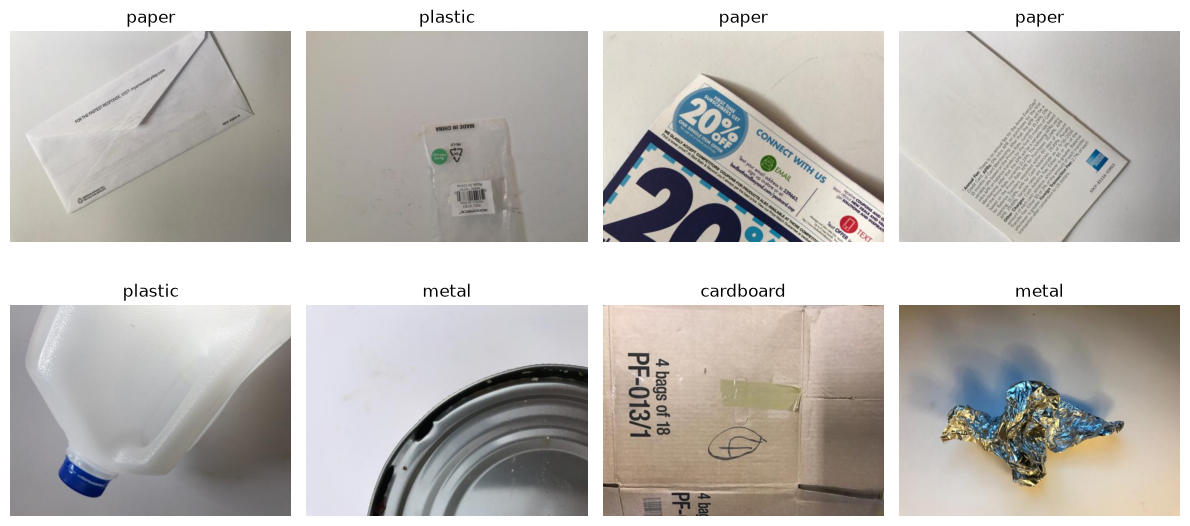

In [ ]:
# ---------- 1. Данные ----------
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
data_dir = os.path.join(path, "Garbage classification", "Garbage classification")

full_ds = datasets.ImageFolder(root=data_dir, transform=None)
class_names = full_ds.classes
num_classes = len(class_names)
print("Классы:", class_names)
print("Всего изображений:", len(full_ds))

# Размеры
sample_img, sample_label = full_ds[0]
print("Форма изображения:", np.array(sample_img).shape)
print("Метка (пример):", sample_label)

# Показ примеров
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(full_ds)-1)
    img, lbl = full_ds[idx]
    ax.imshow(img)
    ax.set_title(class_names[lbl])
    ax.axis("off")
plt.tight_layout()
plt.show()



In [ ]:
# ---------- 2. Трансформации и сплит ----------
IMG_SIZE = 224
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE), 
        #Случайно выбирает участок с\
        #изменяемыми масштабом и соотношением сторон,\
        # затем масштабирует его к 224×224. 
    transforms.RandomHorizontalFlip(),
        #С вероятностью p=0.5 отражает картинку горизонтально
    transforms.ToTensor(),
        #Переводит PIL RGB в torch.Tensor размера [3,H,W];
        #для обычного 8-битного изображения переводит пиксели 0…255 в [0,1].
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        #По каждому RGB-каналу считает (x − mean)/std. 
        #Числа [0.485,0.456,0.406] — средние значения каналов R/G/B,
        #а [0.229,0.224,0.225] — стандартные отклонения для ImageNet.
])
val_tf = transforms.Compose([
    transforms.Resize(256),
    #При целочисленном аргументе масштабирует
    #меньшую сторону изображения до 256, сохраняя пропорции.
    transforms.CenterCrop(IMG_SIZE),
    #Вырезает центральный квадрат 224×224.
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 70/15/15
n_total = len(full_ds)
n_train = int(0.7 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_ds, val_ds, test_ds = random_split(
    full_ds, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)

class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, lbl = self.subset[idx]
        return self.transform(img), lbl

train_ds = TransformedSubset(train_ds, train_tf)
val_ds   = TransformedSubset(val_ds, val_tf)
test_ds  = TransformedSubset(test_ds, val_tf)

batch_size = 32
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")



Train: 1768, Val: 379, Test: 380


In [ ]:
# ---------- 3. Модели ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
def build_model(name, pretrained=False):
    if name == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.resnet18(weights=weights)
        # у нас не 1000 классов а 6, поэтому последний слой меняем
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "resnet50":
        weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        m = models.resnet50(weights=weights)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.efficientnet_b0(weights=weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif name == "convnext_tiny":
        weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.convnext_tiny(weights=weights)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, num_classes)
    return m.to(device)




cuda


In [20]:
print(device)

cuda


In [ ]:
# ---------- 4. Обучение ----------
model_names = ["convnext_tiny", "resnet18", "resnet50", "efficientnet_b0"]

def train_epoch(model, loader, criterion, optimizer, metric):
    model.train()
    metric.reset()
    total_loss = 0.0
    n = 0
    pbar = tqdm(loader, leave=False, desc="train", mininterval=0.5)
    for imgs, lbls in pbar:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()

        preds = out.argmax(dim=1)
        metric.update(preds, lbls)

        total_loss += loss.item() * imgs.size(0) # среднее по 32 изображениям умножается на 32
        n += imgs.size(0)
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    train_f1 = metric.compute().item()
    train_loss = total_loss / n
    return train_loss, train_f1

@torch.no_grad() #Отключает отслеживание градиентов и построение графа вычислений.
def evaluate(model, loader, metric):
    model.eval()
    metric.reset()
    for imgs, lbls in tqdm(loader, leave=False, desc="val", mininterval=0.5):
        imgs, lbls = imgs.to(device), lbls.to(device)
        preds = model(imgs).argmax(dim=1) #находим среди 6 классов тот у кого вероятность больше
        metric.update(preds, lbls)
    return metric.compute().item()


def run_experiment(model_name, pretrained, epochs=20, lr=1e-3):
    model = build_model(model_name, pretrained).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    train_metric = MulticlassF1Score(
        num_classes=num_classes, average="macro"
    ).to(device)
    val_metric = MulticlassF1Score(
        num_classes=num_classes, average="macro"
    ).to(device)

    val_history = []
    train_history = []

    # Для сохранения лучшей модели
    best_val_f1 = -1.0
    best_epoch = 0
    best_model_state = None

    for ep in range(epochs):
        train_loss, train_f1 = train_epoch(
            model, train_loader, criterion, optimizer, train_metric
        )

        val_f1 = evaluate(model, val_loader, val_metric)

        val_history.append(val_f1)
        train_history.append(train_f1)

        # Если модель стала лучше, сохраняем её веса
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = ep + 1
            best_model_state = copy.deepcopy(model.state_dict())

        print(
            f"[{model_name} | pretrained={pretrained}] epoch {ep+1}: "
            f"train loss={train_loss:.4f}, train macro-F1={train_f1:.4f} | "
            f"val macro-F1={val_f1:.4f}",
            flush=True,
        )

    # Восстанавливаем веса лучшей эпохи
    model.load_state_dict(best_model_state)

    print(
        f"BEST MODEL: epoch {best_epoch}, "
        f"val macro-F1={best_val_f1:.4f}",
        flush=True,
    )

    return model, {"train": train_history, "val": val_history}


# 8 экспериментов
results = {}
histories = {}
for name in model_names:
    for pretrained in [False, True]:
        key = f"{name}_{'pre' if pretrained else 'scratch'}"
        print(f"\n>>> {key}", flush=True)
        model, hist = run_experiment(name, pretrained, epochs=10)
        results[key] = model
        histories[key] = hist


>>> convnext_tiny_scratch


train:   0%|          | 0/56 [00:00<?, ?it/s]

val:   0%|          | 0/12 [00:00<?, ?it/s]

[convnext_tiny | pretrained=False] epoch 1: train loss=2.0103, train macro-F1=0.2513 | val macro-F1=0.2003


train:   0%|          | 0/56 [00:00<?, ?it/s]

val:   0%|          | 0/12 [00:00<?, ?it/s]

... (231 outputs left out)

[efficientnet_b0 | pretrained=True] epoch 9: train loss=0.3095, train macro-F1=0.8818 | val macro-F1=0.8551


train:   0%|          | 0/56 [00:00<?, ?it/s]

val:   0%|          | 0/12 [00:00<?, ?it/s]

[efficientnet_b0 | pretrained=True] epoch 10: train loss=0.3272, train macro-F1=0.8812 | val macro-F1=0.9007
BEST MODEL: epoch 7, val macro-F1=0.9160


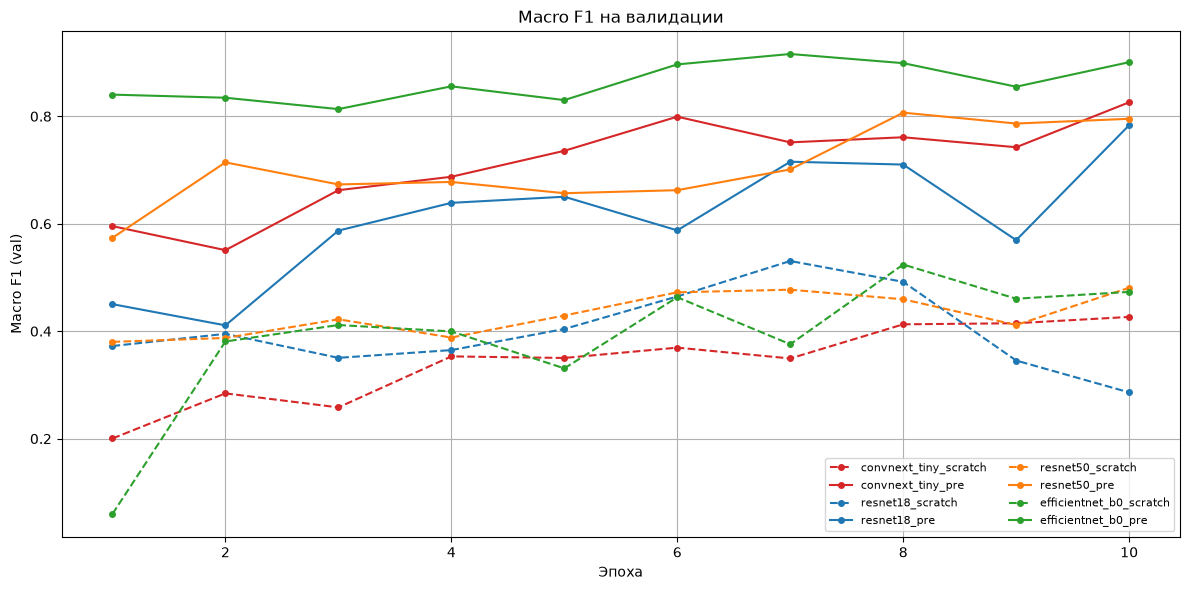

In [ ]:
# ---------- 5. График Macro F1 по эпохам ----------
palette = {
    "resnet18":        "tab:blue",
    "resnet50":        "tab:orange",
    "efficientnet_b0": "tab:green",
    "convnext_tiny":    "tab:red",
}

plt.figure(figsize=(12, 6))
for key, hist in histories.items():
    model_name = key.rsplit("_", 1)[0]
    is_pre = key.endswith("_pre")
    style = "-" if is_pre else "--"

    val_hist = hist["val"] if isinstance(hist, dict) else hist

    plt.plot(
        range(1, len(val_hist) + 1), val_hist,
        marker="o", markersize=4,
        color=palette.get(model_name, "gray"),
        linestyle=style,
        label=key,
    )

plt.xlabel("Эпоха")
plt.ylabel("Macro F1 (val)")
plt.title("Macro F1 на валидации")
plt.legend(fontsize=8, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

val:   0%|          | 0/12 [00:00<?, ?it/s]

convnext_tiny_scratch: test macro-F1 = 0.4276


val:   0%|          | 0/12 [00:00<?, ?it/s]

convnext_tiny_pre: test macro-F1 = 0.7959


val:   0%|          | 0/12 [00:00<?, ?it/s]

resnet18_scratch: test macro-F1 = 0.4917


... (6 outputs left out)

val:   0%|          | 0/12 [00:00<?, ?it/s]

efficientnet_b0_scratch: test macro-F1 = 0.5243


val:   0%|          | 0/12 [00:00<?, ?it/s]

efficientnet_b0_pre: test macro-F1 = 0.8975


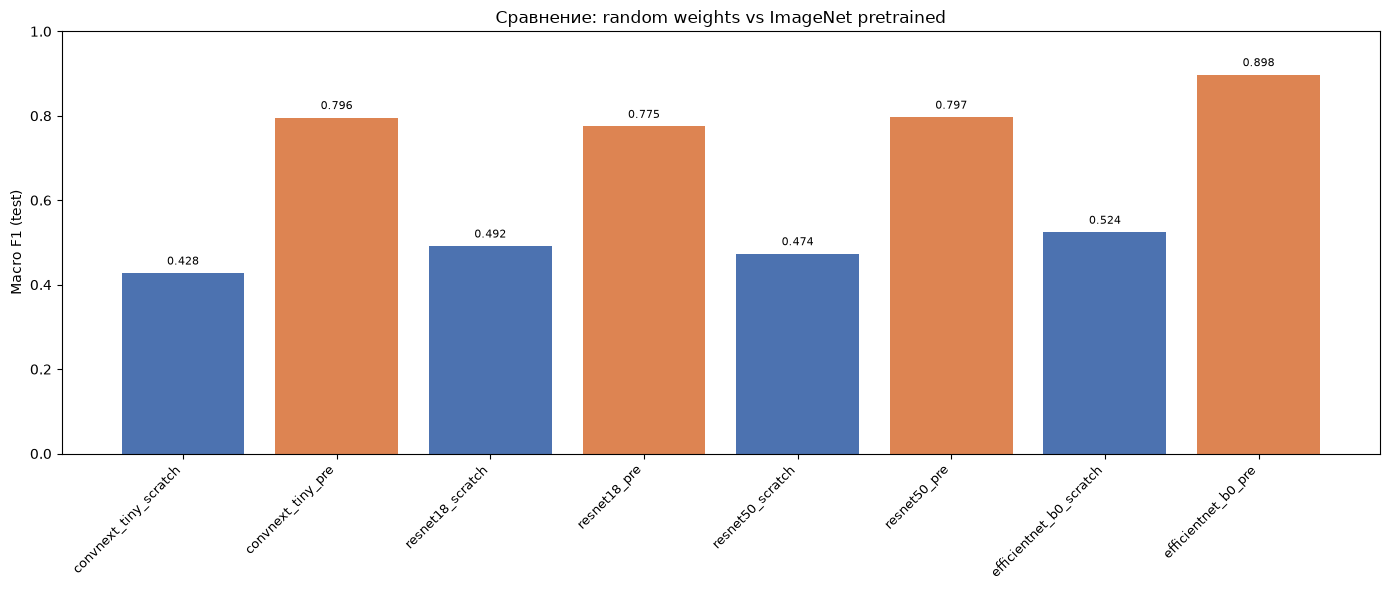


Итог:
efficientnet_b0_pre                 0.8975
resnet50_pre                        0.7968
convnext_tiny_pre                   0.7959
resnet18_pre                        0.7750
efficientnet_b0_scratch             0.5243
resnet18_scratch                    0.4917
resnet50_scratch                    0.4735
convnext_tiny_scratch               0.4276


In [26]:


# ---------- 6. Тестовая оценка и столбчатая диаграмма ----------
test_metric = MulticlassF1Score(num_classes=num_classes, average="macro").to(device)
test_scores = {}
for key, model in results.items():
    test_scores[key] = evaluate(model, test_loader, test_metric)
    print(f"{key}: test macro-F1 = {test_scores[key]:.4f}")

plt.figure(figsize=(14, 6))
keys = list(test_scores.keys())
vals = [test_scores[k] for k in keys]
bars = plt.bar(keys, vals, color=["#4C72B0" if "scratch" in k else "#DD8452" for k in keys])
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.ylabel("Macro F1 (test)")
plt.title("Сравнение: random weights vs ImageNet pretrained")
plt.ylim(0, 1)
for bar, v in zip(bars, vals):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

# Краткая таблица
print("\nИтог:")
for k, v in sorted(test_scores.items(), key=lambda x: -x[1]):
    print(f"{k:35s} {v:.4f}")